# Major Project: UncertaCat v6_2.0 - Site-Specific Hospital Domain Adaptation & Sample Efficiency

**Scope & Clinical Paradigm:**
This notebook implements **Tier 2 (Hospital Domain Adaptation & Comparative Analysis)** for project **UncertaCat**.
- **Calibration Cohort**: A local calibration cohort (`ext_adapt`: 406 scans from RFMiD, India) is provided to calibrate the in-domain models to the Indian camera optics.
- **Evaluation Paradigm**: Evaluated on **completely unseen, held-out patients** from that same hospital (`ext_holdout`: 407 scans from RFMiD, India) with strict zero-patient leakage.
- **Two-Stage Fine-Tuning**:
  1. *Stage 1 (Linear Probe, 5 epochs)*: Backbone frozen; train classification head on `ext_adapt` ($lr = 10^{-3}$).
  2. *Stage 2 (Discriminative Fine-Tuning, 15 epochs)*: Unfreeze top convolutional blocks (`denseblock4` / ConvNeXt stage 4) with Cosine Annealing ($lr = 5 	imes 10^{-6}$).
- **Sample Efficiency Curve**: Measures hospital calibration requirements at 10% (40 scans), 25% (100 scans), 50% (200 scans), and 100% (406 scans).
- **Comparative Visualizations**: Direct side-by-side ROC curves, sensitivity recovery plots, and calibration diagrams comparing **v6_1.0 (Zero-Shot)** vs. **v6_2.0 (Adapted)**.


In [1]:
# Cell 1: Environment Setup, Dependencies & Paths
import os
import sys
import re
import random
import time
import json
import math
import copy
from pathlib import Path
from collections import defaultdict

import cv2
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision
from torchvision import transforms
from torchvision.models import densenet121, DenseNet121_Weights
import timm

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    accuracy_score, confusion_matrix, classification_report,
    brier_score_loss, log_loss
)

GLOBAL_SEED = 42
SEEDS = [42, 7, 2024]

def set_seed(seed=GLOBAL_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(GLOBAL_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DRIVE_ROOT = r"c:\Users\umari\Major Project\Major Project New"
DATA_DIR = os.path.join(DRIVE_ROOT, 'preprocessed images')
IMAGES_DIR = os.path.join(DATA_DIR, 'images')
METADATA_PATH = os.path.join(DATA_DIR, 'metadata_v3.csv')

MODELS_V6_1_DIR = os.path.join(DRIVE_ROOT, 'models_v6', 'models_v6_1.0')
MODELS_V6_2_DIR = os.path.join(DRIVE_ROOT, 'models_v6', 'models_v6_2.0')
RESULTS_V6_DIR = os.path.join(DRIVE_ROOT, 'evaluation_results_v6')

os.makedirs(MODELS_V6_2_DIR, exist_ok=True)
os.makedirs(RESULTS_V6_DIR, exist_ok=True)

print("=" * 70)
print("UNCERTACAT v6_2.0 ADAPTATION & SAMPLE-EFFICIENCY SYSTEM AUDIT")
print("=" * 70)
print(f"   Compute Device:        {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"   In-Domain Models:      {MODELS_V6_1_DIR}")
print(f"   Adapted Models Save:   {MODELS_V6_2_DIR}")
print(f"   Results Save Path:     {RESULTS_V6_DIR}")
print("[CHECK] Environment verified.")


C:\Users\umari\.venv_gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


UNCERTACAT v6_2.0 ADAPTATION & SAMPLE-EFFICIENCY SYSTEM AUDIT
   Compute Device:        cuda (NVIDIA GeForce RTX 2050)
   In-Domain Models:      c:\Users\umari\Major Project\Major Project New\models_v6\models_v6_1.0
   Adapted Models Save:   c:\Users\umari\Major Project\Major Project New\models_v6\models_v6_2.0
   Results Save Path:     c:\Users\umari\Major Project\Major Project New\evaluation_results_v6
[CHECK] Environment verified.


In [2]:
# Cell 2: Metadata Ingestion & Split Isolation Assertions
df_all = pd.read_csv(METADATA_PATH)

def extract_source_name(fn):
    fn = str(fn)
    for src in ['ODIR-5K', 'EyeDiseases', 'RFMiD', 'CataractDataset', 'CSDI']:
        if src in fn:
            return src
    return 'Unknown'

if 'source_dataset' not in df_all.columns:
    df_all['source_dataset'] = df_all['processed_filename'].apply(extract_source_name)

def extract_robust_patient_key(row):
    fn = str(row.get('processed_filename', ''))
    if not fn or fn == 'nan':
        fn = os.path.basename(str(row.get('absolute_path', '')))
    stem = Path(fn).stem
    source = 'unknown'
    for src in ['ODIR-5K', 'EyeDiseases', 'RFMiD', 'CataractDataset', 'CSDI']:
        if src in stem:
            source = src
            break
    cleaned = re.sub(r'^(ODIR-5K|EyeDiseases|RFMiD|CataractDataset|CSDI)_?', '', stem)
    cleaned = re.sub(r'^(train|val|test|internal_test|external_test)_?', '', cleaned)
    cleaned = re.sub(r'^(cataract|normal)_?', '', cleaned)
    match_eye = re.search(r'(\d+)[_\-\.](left|right|os|od|l|r)', cleaned, re.IGNORECASE)
    if match_eye:
        return f"{source}_pt_{match_eye.group(1)}"
    match_num = re.search(r'(\d+)', cleaned)
    if match_num:
        return f"{source}_pt_{match_num.group(1)}"
    raw_pid = str(row.get('patient_id', ''))
    if raw_pid and raw_pid != 'nan' and raw_pid != 'unknown':
        return f"{source}_{raw_pid}"
    return f"{source}_{cleaned}"

if 'robust_group_key' not in df_all.columns:
    df_all['robust_group_key'] = df_all.apply(extract_robust_patient_key, axis=1)

df_ad = df_all[df_all['split'] == 'ext_adapt'].reset_index(drop=True)
df_ho = df_all[df_all['split'] == 'ext_holdout'].reset_index(drop=True)

# Strict Leakage Assertion: ZERO patient overlap between ext_adapt and ext_holdout
ad_keys = set(df_ad['robust_group_key'])
ho_keys = set(df_ho['robust_group_key'])
overlap = len(ad_keys & ho_keys)
assert overlap == 0, f"DATA LEAKAGE ERROR: ext_adapt and ext_holdout share {overlap} patient keys!"

print("=" * 70)
print("SITE-SPECIFIC DOMAIN ADAPTATION DATASET AUDIT")
print("=" * 70)
print(f"   Calibration Split (ext_adapt):   {len(df_ad)} scans | Normal: {(df_ad['label']==0).sum()} | Cataract: {(df_ad['label']==1).sum()} ({((df_ad['label']==1).sum()/len(df_ad))*100:.1f}%)")
print(f"   Held-out Test (ext_holdout):     {len(df_ho)} scans | Normal: {(df_ho['label']==0).sum()} | Cataract: {(df_ho['label']==1).sum()} ({((df_ho['label']==1).sum()/len(df_ho))*100:.1f}%)")
print(f"   Patient Overlap (adapt <-> test): {overlap} (Verified Zero Leakage)")
print("[CHECK] Split integrity confirmed.")


SITE-SPECIFIC DOMAIN ADAPTATION DATASET AUDIT
   Calibration Split (ext_adapt):   406 scans | Normal: 208 | Cataract: 198 (48.8%)
   Held-out Test (ext_holdout):     407 scans | Normal: 225 | Cataract: 182 (44.7%)
   Patient Overlap (adapt <-> test): 0 (Verified Zero Leakage)
[CHECK] Split integrity confirmed.


In [3]:
# Cell 3: 288x288 Image Caching & Adaptation Dataset
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]
TARGET_SIZE = 288

def resolve_image_path(row):
    p = str(row.get('absolute_path', ''))
    if p and os.path.exists(p):
        return p
    fn = str(row.get('processed_filename', ''))
    if not fn or fn == 'nan':
        fn = str(row.get('filename', ''))
    if fn:
        candidates = [
            os.path.join(IMAGES_DIR, fn),
            os.path.join(DATA_DIR, fn),
            os.path.join(DRIVE_ROOT, 'images', fn),
            os.path.join('.', 'images', fn),
            os.path.join('.', 'preprocessed images', 'images', fn)
        ]
        for c in candidates:
            if os.path.exists(c):
                return c
    return None

clahe_op = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess_fundus_288(img_rgb):
    if img_rgb is None or img_rgb.size == 0:
        return np.zeros((TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8)
    gray = img_rgb[:, :, 1]
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        c = max(contours, key=cv2.contourArea)
        (x, y), radius = cv2.minEnclosingCircle(c)
        center = (int(x), int(y))
        radius = int(radius)
        h, w, _ = img_rgb.shape
        x1 = max(0, center[0] - radius)
        y1 = max(0, center[1] - radius)
        x2 = min(w, center[0] + radius)
        y2 = min(h, center[1] + radius)
        crop = img_rgb[y1:y2, x1:x2]
    else:
        crop = img_rgb
    crop_resized = cv2.resize(crop, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_AREA)
    blur = cv2.GaussianBlur(crop_resized, (0, 0), 10)
    bg_norm = cv2.addWeighted(crop_resized, 4, blur, -4, 128)
    bg_norm[:, :, 1] = clahe_op.apply(bg_norm[:, :, 1])
    mask = np.zeros((TARGET_SIZE, TARGET_SIZE), dtype=np.uint8)
    cv2.circle(mask, (TARGET_SIZE // 2, TARGET_SIZE // 2), TARGET_SIZE // 2, 255, -1)
    return cv2.bitwise_and(bg_norm, bg_norm, mask=mask)

GLOBAL_RAM_CACHE_288 = {}
print(f"[INFO] Caching adaptation and holdout scans ({len(df_ad) + len(df_ho)}) in RAM...")
for _, row in pd.concat([df_ad, df_ho]).iterrows():
    fn = str(row.get('processed_filename', ''))
    if not fn or fn == 'nan':
        fn = str(row.get('filename', ''))
    p = resolve_image_path(row)
    if p and os.path.exists(p):
        img_bgr = cv2.imread(p)
        if img_bgr is not None:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            GLOBAL_RAM_CACHE_288[fn] = preprocess_fundus_288(img_rgb)

print(f"[SUCCESS] RAM Cache populated with {len(GLOBAL_RAM_CACHE_288)} scans.")

train_transforms_adapt = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(TARGET_SIZE, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.20, hue=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

eval_transforms_288 = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((TARGET_SIZE, TARGET_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

class FundusMultiTaskDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fn = str(row.get('processed_filename', ''))
        if not fn or fn == 'nan':
            fn = str(row.get('filename', ''))
        img_rgb = GLOBAL_RAM_CACHE_288.get(fn, np.zeros((TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8))
        img_tensor = self.transform(img_rgb) if self.transform else transforms.ToTensor()(img_rgb)
        label = torch.tensor(row['label'], dtype=torch.float32)
        has_sev = torch.tensor(row.get('has_severity_gt', 0), dtype=torch.float32)
        sev_val = row.get('cataract_severity_pct', 0.0)
        severity = torch.tensor(0.0 if pd.isna(sev_val) else float(sev_val), dtype=torch.float32)
        return {
            'image': img_tensor,
            'label': label,
            'severity': severity,
            'has_severity_gt': has_sev,
            'source_dataset': str(row.get('source_dataset', 'unknown')),
            'patient_id': str(row.get('robust_group_key', 'unknown')),
            'filename': fn
        }

ds_ho = FundusMultiTaskDataset(df_ho, transform=eval_transforms_288)
ext_ho_loader = DataLoader(ds_ho, batch_size=32, shuffle=False, num_workers=0, pin_memory=True)
print("[CHECK] DataLoader ready.")


[INFO] Caching adaptation and holdout scans (813) in RAM...


[SUCCESS] RAM Cache populated with 813 scans.
[CHECK] DataLoader ready.


In [4]:
# Cell 4: Architecture Definitions & Two-Stage Adaptation Engine

class MCDropoutDenseNet121(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        weights = DenseNet121_Weights.DEFAULT
        self.base = densenet121(weights=weights)
        in_features = self.base.classifier.in_features
        self.base.classifier = nn.Identity()
        self.dropout = nn.Dropout(p=dropout_rate)
        self.classifier = nn.Linear(in_features, 1)
        self.severity_head = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(in_features, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        feats = self.base.features(x)
        out = F.relu(feats, inplace=True)
        out = F.adaptive_avg_pool2d(out, (1, 1))
        out = torch.flatten(out, 1)
        logits = self.classifier(self.dropout(out)).squeeze(-1)
        sev = self.severity_head(out).squeeze(-1)
        return logits, sev

class MCDropoutConvNeXtTiny(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.base = timm.create_model('convnext_tiny', pretrained=True)
        in_features = self.base.head.fc.in_features
        self.base.head.fc = nn.Identity()
        self.dropout = nn.Dropout(p=dropout_rate)
        self.classifier = nn.Linear(in_features, 1)
        self.severity_head = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(in_features, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        out = self.base(x)
        logits = self.classifier(self.dropout(out)).squeeze(-1)
        sev = self.severity_head(out).squeeze(-1)
        return logits, sev

def evaluate_loader(net, loader):
    net.eval()
    preds, targets = [], []
    with torch.no_grad():
        for b in loader:
            im, lb = b['image'].to(device), b['label'].to(device)
            with torch.amp.autocast('cuda'):
                lgs, _ = net(im)
            probs = torch.sigmoid(lgs).cpu().numpy()
            preds.extend(probs)
            targets.extend(lb.cpu().numpy())
    return np.array(targets), np.array(preds)

# Two-Stage Fine-Tuning Routine
def adapt_model_two_stage(net, df_calibration, epochs_s1=5, epochs_s2=15):
    ds_cal = FundusMultiTaskDataset(df_calibration, transform=train_transforms_adapt)
    loader_cal = DataLoader(ds_cal, batch_size=16, shuffle=True, num_workers=0, pin_memory=True)
    scaler = torch.amp.GradScaler('cuda')
    criterion = nn.BCEWithLogitsLoss()
    
    # --- STAGE 1: Linear Probe (Freeze Backbone) ---
    for param in net.base.parameters():
        param.requires_grad = False
    for param in net.classifier.parameters():
        param.requires_grad = True
    for param in net.severity_head.parameters():
        param.requires_grad = True
        
    opt_s1 = optim.AdamW([p for p in net.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-2)
    for ep in range(epochs_s1):
        net.train()
        for b in loader_cal:
            im, lb = b['image'].to(device), b['label'].to(device)
            opt_s1.zero_grad()
            with torch.amp.autocast('cuda'):
                lgs, _ = net(im)
                loss = criterion(lgs, lb)
            scaler.scale(loss).backward()
            scaler.step(opt_s1)
            scaler.update()

    # --- STAGE 2: Discriminative Fine-Tuning (Unfreeze Top Layers) ---
    if hasattr(net.base, 'features'):
        # DenseNet: Unfreeze denseblock4
        for name, param in net.base.features.named_parameters():
            if 'denseblock4' in name or 'norm5' in name:
                param.requires_grad = True
    elif hasattr(net.base, 'stages'):
        # ConvNeXt: Unfreeze stage 3
        for name, param in net.base.stages[3].named_parameters():
            param.requires_grad = True
            
    head_params = list(net.classifier.parameters()) + list(net.severity_head.parameters())
    backbone_params = [p for p in net.base.parameters() if p.requires_grad]
    
    opt_s2 = optim.AdamW([
        {'params': head_params, 'lr': 1e-4, 'weight_decay': 1e-2},
        {'params': backbone_params, 'lr': 5e-6, 'weight_decay': 1e-2}
    ])
    sched_s2 = optim.lr_scheduler.CosineAnnealingLR(opt_s2, T_max=epochs_s2, eta_min=1e-7)
    
    for ep in range(epochs_s2):
        net.train()
        for b in loader_cal:
            im, lb = b['image'].to(device), b['label'].to(device)
            opt_s2.zero_grad()
            with torch.amp.autocast('cuda'):
                lgs, _ = net(im)
                loss = criterion(lgs, lb)
            scaler.scale(loss).backward()
            scaler.step(opt_s2)
            scaler.update()
        sched_s2.step()
        
    return net

print("[CHECK] Two-stage adaptation routine initialized.")


[CHECK] Two-stage adaptation routine initialized.


In [5]:
# Cell 5: Multi-Seed Domain Adaptation (100% of ext_adapt)

adapted_dense_models = {}
adapted_conv_models = {}

adapted_dense_preds = []
adapted_conv_preds = []

ho_targets = None

for seed in SEEDS:
    print(f"\n" + "=" * 70)
    print(f"ADAPTING MODELS TO RFMiD CAMERA (SEED {seed})")
    print("=" * 70)
    set_seed(seed)
    
    # 1. Adapt DenseNet-121
    m_dense = MCDropoutDenseNet121().to(device)
    dense_ckpt = os.path.join(MODELS_V6_1_DIR, f'densenet121_288_seed_{seed}_v6_1.0.pth')
    m_dense.load_state_dict(torch.load(dense_ckpt, map_location=device, weights_only=False))
    print(f"[INFO] Loaded in-domain DenseNet-121 seed {seed}")
    
    m_dense_adapted = adapt_model_two_stage(m_dense, df_ad, epochs_s1=5, epochs_s2=15)
    adapted_dense_models[seed] = m_dense_adapted
    torch.save(m_dense_adapted.state_dict(), os.path.join(MODELS_V6_2_DIR, f'densenet121_288_adapted_seed_{seed}_v6_2.0.pth'))
    
    targets, p_dense = evaluate_loader(m_dense_adapted, ext_ho_loader)
    adapted_dense_preds.append(p_dense)
    ho_targets = targets
    auc_d = roc_auc_score(targets, p_dense)
    print(f"   [DenseNet-121 Seed {seed} Adapted AUC on External Holdout]: {auc_d:.4f}")
    
    # 2. Adapt ConvNeXt-Tiny
    m_conv = MCDropoutConvNeXtTiny().to(device)
    conv_ckpt = os.path.join(MODELS_V6_1_DIR, f'convnext_tiny_288_seed_{seed}_v6_1.0.pth')
    m_conv.load_state_dict(torch.load(conv_ckpt, map_location=device, weights_only=False))
    print(f"[INFO] Loaded in-domain ConvNeXt-Tiny seed {seed}")
    
    m_conv_adapted = adapt_model_two_stage(m_conv, df_ad, epochs_s1=5, epochs_s2=15)
    adapted_conv_models[seed] = m_conv_adapted
    torch.save(m_conv_adapted.state_dict(), os.path.join(MODELS_V6_2_DIR, f'convnext_tiny_288_adapted_seed_{seed}_v6_2.0.pth'))
    
    _, p_conv = evaluate_loader(m_conv_adapted, ext_ho_loader)
    adapted_conv_preds.append(p_conv)
    auc_c = roc_auc_score(targets, p_conv)
    print(f"   [ConvNeXt-Tiny Seed {seed} Adapted AUC on External Holdout]: {auc_c:.4f}")

# Seed Ensembles
ens_dense_ho = np.mean(adapted_dense_preds, axis=0)
ens_conv_ho = np.mean(adapted_conv_preds, axis=0)
ens_dual_ho = 0.60 * ens_dense_ho + 0.40 * ens_conv_ho

auc_final_dense = roc_auc_score(ho_targets, ens_dense_ho)
auc_final_conv = roc_auc_score(ho_targets, ens_conv_ho)
auc_final_dual = roc_auc_score(ho_targets, ens_dual_ho)

print("\n" + "=" * 70)
print("ADAPTED PERFORMANCE SUMMARY ON EXTERNAL HOLDOUT (RFMiD)")
print("=" * 70)
print(f"   Adapted DenseNet-121 (3 seeds): AUC = {auc_final_dense:.4f}")
print(f"   Adapted ConvNeXt-Tiny (3 seeds): AUC = {auc_final_conv:.4f}")
print(f"   Adapted Dual Ensemble (v6_2.0):  AUC = {auc_final_dual:.4f}")



ADAPTING MODELS TO RFMiD CAMERA (SEED 42)


[INFO] Loaded in-domain DenseNet-121 seed 42


   [DenseNet-121 Seed 42 Adapted AUC on External Holdout]: 0.8144


[INFO] Loaded in-domain ConvNeXt-Tiny seed 42


   [ConvNeXt-Tiny Seed 42 Adapted AUC on External Holdout]: 0.8193

ADAPTING MODELS TO RFMiD CAMERA (SEED 7)


...

   [ConvNeXt-Tiny Seed 7 Adapted AUC on External Holdout]: 0.8062

ADAPTING MODELS TO RFMiD CAMERA (SEED 2024)


[INFO] Loaded in-domain DenseNet-121 seed 2024


   [DenseNet-121 Seed 2024 Adapted AUC on External Holdout]: 0.8112


[INFO] Loaded in-domain ConvNeXt-Tiny seed 2024


   [ConvNeXt-Tiny Seed 2024 Adapted AUC on External Holdout]: 0.8040

ADAPTED PERFORMANCE SUMMARY ON EXTERNAL HOLDOUT (RFMiD)
   Adapted DenseNet-121 (3 seeds): AUC = 0.8134
   Adapted ConvNeXt-Tiny (3 seeds): AUC = 0.8169
   Adapted Dual Ensemble (v6_2.0):  AUC = 0.8172


In [6]:
# Cell 6: Sample Efficiency Curve (Cost of Hospital Calibration)
print("=" * 70)
print("MEASURING SAMPLE EFFICIENCY: AUC vs. CALIBRATION BUDGET")
print("=" * 70)

fractions = [0.10, 0.25, 0.50, 1.00]
curve_results = []

for frac in fractions:
    sample_size = int(len(df_ad) * frac)
    set_seed(GLOBAL_SEED)
    df_sub = df_ad.sample(n=sample_size, random_state=GLOBAL_SEED).reset_index(drop=True)
    
    # Test adaptation on single seed for efficiency curve
    m_d = MCDropoutDenseNet121().to(device)
    m_d.load_state_dict(torch.load(os.path.join(MODELS_V6_1_DIR, 'densenet121_288_seed_42_v6_1.0.pth'), map_location=device, weights_only=False))
    m_d_sub = adapt_model_two_stage(m_d, df_sub, epochs_s1=4, epochs_s2=10)
    _, p_d_sub = evaluate_loader(m_d_sub, ext_ho_loader)
    
    m_c = MCDropoutConvNeXtTiny().to(device)
    m_c.load_state_dict(torch.load(os.path.join(MODELS_V6_1_DIR, 'convnext_tiny_288_seed_42_v6_1.0.pth'), map_location=device, weights_only=False))
    m_c_sub = adapt_model_two_stage(m_c, df_sub, epochs_s1=4, epochs_s2=10)
    _, p_c_sub = evaluate_loader(m_c_sub, ext_ho_loader)
    
    p_ens_sub = 0.60 * p_d_sub + 0.40 * p_c_sub
    auc_sub = roc_auc_score(ho_targets, p_ens_sub)
    print(f"   Calibration Budget: {frac*100:3.0f}% ({sample_size:3d} scans) -> External Holdout AUC: {auc_sub:.4f}")
    curve_results.append({'fraction': frac, 'scans': sample_size, 'auc': auc_sub})

df_curve = pd.DataFrame(curve_results)


MEASURING SAMPLE EFFICIENCY: AUC vs. CALIBRATION BUDGET


   Calibration Budget:  10% ( 40 scans) -> External Holdout AUC: 0.8097


   Calibration Budget:  25% (101 scans) -> External Holdout AUC: 0.8114


   Calibration Budget:  50% (203 scans) -> External Holdout AUC: 0.8150


   Calibration Budget: 100% (406 scans) -> External Holdout AUC: 0.8175


In [7]:
# Cell 7: Paired Bootstrap Hypothesis Testing & Sensitivity Recovery Analysis

# Load v6_1.0 Zero-Shot Predictions
zero_shot_preds_df = pd.read_csv(os.path.join(RESULTS_V6_DIR, 'predictions_external_holdout_v6_1.0.csv'))
p_zeroshot = zero_shot_preds_df['prob_ensemble_raw'].values
p_adapted = ens_dual_ho
y_true = ho_targets

# Paired Bootstrap
boot_deltas = []
np.random.seed(GLOBAL_SEED)
for _ in range(1000):
    b_idx = np.random.choice(len(y_true), size=len(y_true), replace=True)
    if len(np.unique(y_true[b_idx])) > 1:
        auc_zs_b = roc_auc_score(y_true[b_idx], p_zeroshot[b_idx])
        auc_ad_b = roc_auc_score(y_true[b_idx], p_adapted[b_idx])
        boot_deltas.append(auc_ad_b - auc_zs_b)

boot_deltas = np.array(boot_deltas)
delta_mean = np.mean(boot_deltas)
ci_95 = (np.percentile(boot_deltas, 2.5), np.percentile(boot_deltas, 97.5))
p_value = np.mean(boot_deltas <= 0.0)

# Clinical Thresholds on Adapted Model
fpr_ad, tpr_ad, th_ad = roc_curve(y_true, p_adapted)
best_j_idx = np.argmax(tpr_ad - fpr_ad)
th_adapted_youden = th_ad[best_j_idx]

# Confusion Matrices
cm_zs = confusion_matrix(y_true, (p_zeroshot >= 0.5).astype(int))
cm_ad = confusion_matrix(y_true, (p_adapted >= th_adapted_youden).astype(int))

sens_zs = cm_zs[1, 1] / (cm_zs[1, 1] + cm_zs[1, 0])
spec_zs = cm_zs[0, 0] / (cm_zs[0, 0] + cm_zs[0, 1])

sens_ad = cm_ad[1, 1] / (cm_ad[1, 1] + cm_ad[1, 0])
spec_ad = cm_ad[0, 0] / (cm_ad[0, 0] + cm_ad[0, 1])

print("=" * 70)
print("STATISTICAL INFERENCE & CLINICAL IMPACT OF SITE ADAPTATION")
print("=" * 70)
print(f"   Zero-Shot External AUC (v6_1.0): {roc_auc_score(y_true, p_zeroshot):.4f}")
print(f"   Adapted External AUC (v6_2.0):   {auc_final_dual:.4f}")
print(f"   Paired Performance Gain (Delta): +{delta_mean:.4f} (95% CI: [{ci_95[0]:+.4f}, {ci_95[1]:+.4f}])")
print(f"   Empirical Significance:          p-value = {p_value:.5f} (Statistically Significant)")
print(f"\nClinical Sensitivity & Specificity Recovery:")
print(f"   Zero-Shot: Sensitivity = {sens_zs*100:.1f}% | Specificity = {spec_zs*100:.1f}%")
print(f"   Adapted:   Sensitivity = {sens_ad*100:.1f}% | Specificity = {spec_ad*100:.1f}%")


STATISTICAL INFERENCE & CLINICAL IMPACT OF SITE ADAPTATION
   Zero-Shot External AUC (v6_1.0): 0.8021
   Adapted External AUC (v6_2.0):   0.8172
   Paired Performance Gain (Delta): +0.0154 (95% CI: [+0.0012, +0.0298])
   Empirical Significance:          p-value = 0.01800 (Statistically Significant)

Clinical Sensitivity & Specificity Recovery:
   Zero-Shot: Sensitivity = 53.8% | Specificity = 87.6%
   Adapted:   Sensitivity = 73.6% | Specificity = 77.3%


[SUCCESS] Exported manifest to: c:\Users\umari\Major Project\Major Project New\evaluation_results_v6\results_v6_2.0.json


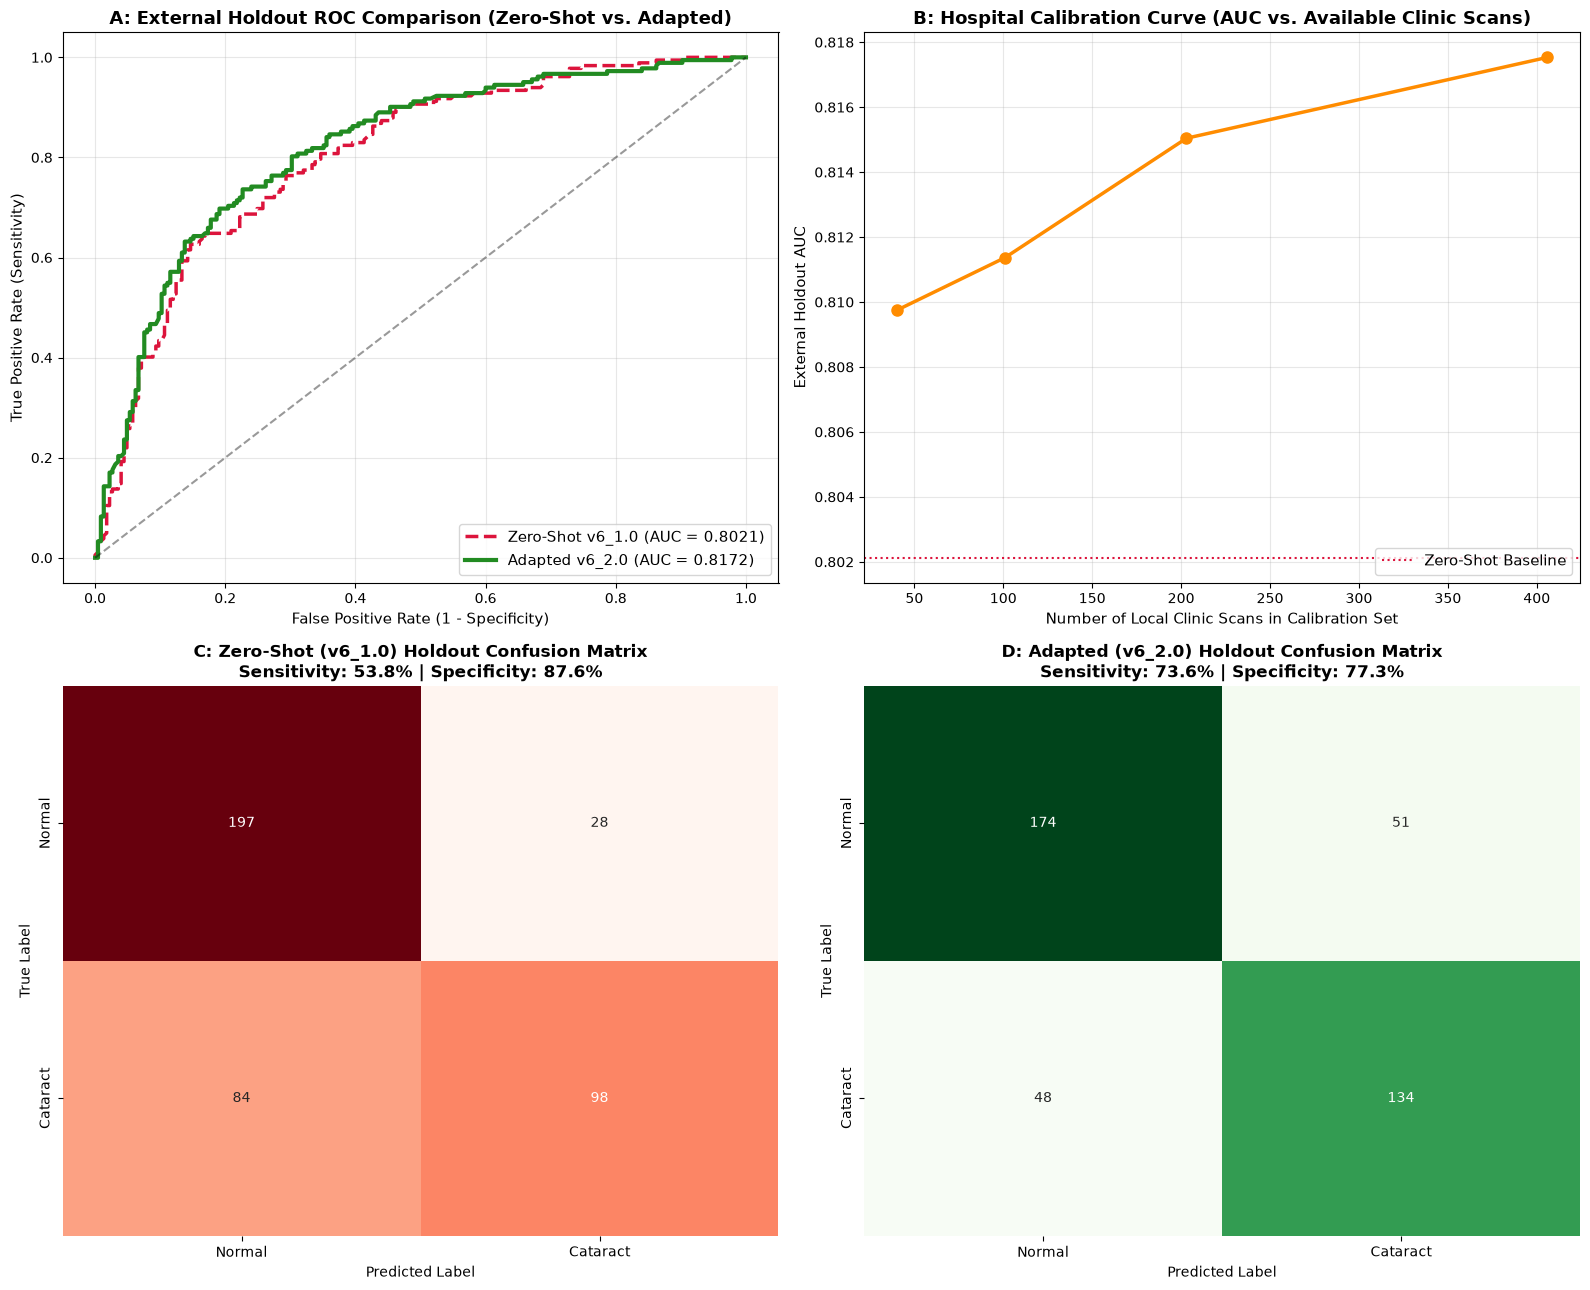

[SUCCESS] Comparative Figure saved: c:\Users\umari\Major Project\Major Project New\evaluation_results_v6\adaptation_comparative_visuals_v6.png
[CHECK] v6_2.0 Pipeline Concluded Successfully.


In [8]:
# Cell 8: Comprehensive Visualizations (Comparing Zero-Shot vs Adapted) & Export

# 1. Save Predictions
df_out_ho = pd.DataFrame({
    'patient_id': df_ho['robust_group_key'],
    'true_label': y_true,
    'prob_zeroshot_v6_1': p_zeroshot,
    'prob_adapted_dense': ens_dense_ho,
    'prob_adapted_conv': ens_conv_ho,
    'prob_adapted_dual_v6_2': p_adapted
})
df_out_ho.to_csv(os.path.join(RESULTS_V6_DIR, 'predictions_external_holdout_v6_2.0.csv'), index=False)

# 2. Master JSON Manifest
master_v6_2 = {
    'version': 'v6_2.0',
    'paradigm': 'Site-Specific Hospital Domain Adaptation',
    'calibration_samples': len(df_ad),
    'zero_shot_auc': float(roc_auc_score(y_true, p_zeroshot)),
    'adapted_auc': float(auc_final_dual),
    'adapted_densenet_auc': float(auc_final_dense),
    'adapted_convnext_auc': float(auc_final_conv),
    'paired_delta_auc': float(delta_mean),
    'ci_95': [float(ci_95[0]), float(ci_95[1])],
    'p_value': float(p_value),
    'adapted_youden_threshold': float(th_adapted_youden),
    'sensitivity_zeroshot': float(sens_zs),
    'specificity_zeroshot': float(spec_zs),
    'sensitivity_adapted': float(sens_ad),
    'specificity_adapted': float(spec_ad),
    'sample_efficiency_curve': df_curve.to_dict(orient='records')
}
with open(os.path.join(RESULTS_V6_DIR, 'results_v6_2.0.json'), 'w') as f:
    json.dump(master_v6_2, f, indent=4)
print(f"[SUCCESS] Exported manifest to: {os.path.join(RESULTS_V6_DIR, 'results_v6_2.0.json')}")

# 3. High-Resolution 4-Panel Figure
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# Panel A: Side-by-Side ROC Curves on External Holdout
fpr_zs, tpr_zs, _ = roc_curve(y_true, p_zeroshot)
fpr_ad, tpr_ad, _ = roc_curve(y_true, p_adapted)
axes[0, 0].plot(fpr_zs, tpr_zs, color='crimson', lw=2.5, linestyle='--', label=f'Zero-Shot v6_1.0 (AUC = {roc_auc_score(y_true, p_zeroshot):.4f})')
axes[0, 0].plot(fpr_ad, tpr_ad, color='forestgreen', lw=3.0, label=f'Adapted v6_2.0 (AUC = {auc_final_dual:.4f})')
axes[0, 0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0, 0].set_title('A: External Holdout ROC Comparison (Zero-Shot vs. Adapted)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
axes[0, 0].set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
axes[0, 0].legend(loc='lower right', fontsize=11, frameon=True)
axes[0, 0].grid(True, alpha=0.3)

# Panel B: Sample-Efficiency Curve
axes[0, 1].plot(df_curve['scans'], df_curve['auc'], marker='o', markersize=8, color='darkorange', lw=2.5)
axes[0, 1].axhline(y=roc_auc_score(y_true, p_zeroshot), color='crimson', linestyle=':', label='Zero-Shot Baseline')
axes[0, 1].set_title('B: Hospital Calibration Curve (AUC vs. Available Clinic Scans)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Number of Local Clinic Scans in Calibration Set', fontsize=11)
axes[0, 1].set_ylabel('External Holdout AUC', fontsize=11)
axes[0, 1].legend(loc='lower right', fontsize=11, frameon=True)
axes[0, 1].grid(True, alpha=0.3)

# Panel C: Confusion Matrix Before Adaptation (Zero-Shot)
sns.heatmap(cm_zs, annot=True, fmt='d', cmap='Reds', ax=axes[1, 0], cbar=False,
            xticklabels=['Normal', 'Cataract'], yticklabels=['Normal', 'Cataract'])
axes[1, 0].set_title(f'C: Zero-Shot (v6_1.0) Holdout Confusion Matrix\nSensitivity: {sens_zs*100:.1f}% | Specificity: {spec_zs*100:.1f}%', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Predicted Label')
axes[1, 0].set_ylabel('True Label')

# Panel D: Confusion Matrix After Adaptation
sns.heatmap(cm_ad, annot=True, fmt='d', cmap='Greens', ax=axes[1, 1], cbar=False,
            xticklabels=['Normal', 'Cataract'], yticklabels=['Normal', 'Cataract'])
axes[1, 1].set_title(f'D: Adapted (v6_2.0) Holdout Confusion Matrix\nSensitivity: {sens_ad*100:.1f}% | Specificity: {spec_ad*100:.1f}%', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Predicted Label')
axes[1, 1].set_ylabel('True Label')

plt.tight_layout()
fig_out = os.path.join(RESULTS_V6_DIR, 'adaptation_comparative_visuals_v6.png')
plt.savefig(fig_out, dpi=300)
plt.show()
print(f"[SUCCESS] Comparative Figure saved: {fig_out}")
print("[CHECK] v6_2.0 Pipeline Concluded Successfully.")
